In [1]:
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
import numpy as np
import healpy as hp

In [3]:
NSIDE = 32
print(
    "Approximate resolution at NSIDE {} is {:.2} deg".format(
        NSIDE, hp.nside2resol(NSIDE, arcmin=True) / 60
    )
)

Approximate resolution at NSIDE 32 is 1.8 deg


In [4]:
NPIX = hp.nside2npix(NSIDE)
print(NPIX)

12288


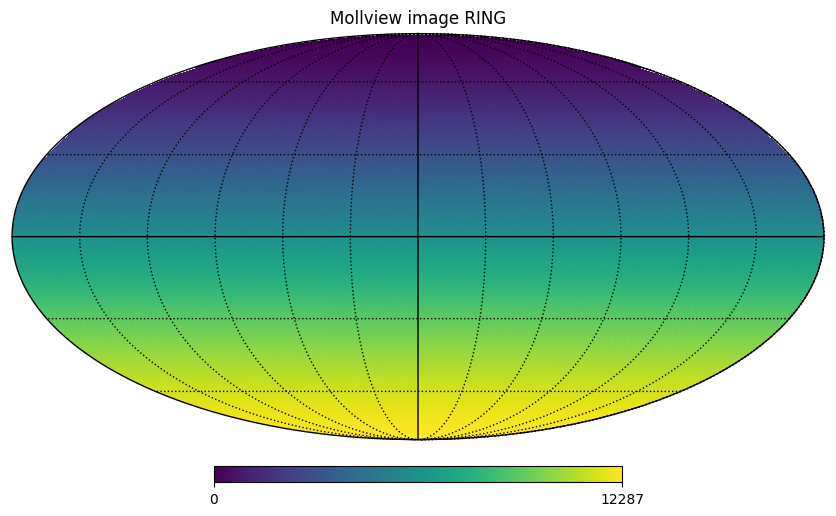

In [5]:
m = np.arange(NPIX)
hp.mollview(m, title="Mollview image RING")
hp.graticule()

In [6]:
vec = hp.ang2vec(np.pi / 2, np.pi * 3 / 4)
print(vec)

[-7.07106781e-01  7.07106781e-01  6.12323400e-17]


In [7]:
ipix_disc = hp.query_disc(nside=32, vec=vec, radius=np.radians(10))

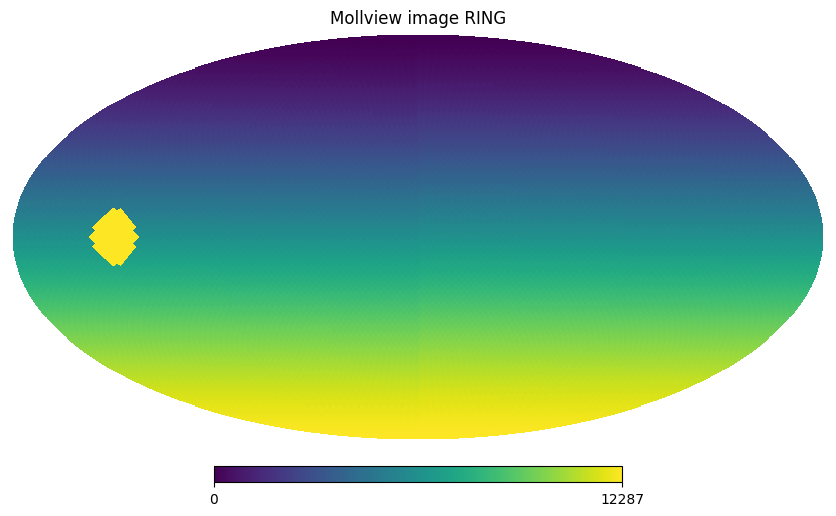

In [8]:
m = np.arange(NPIX)
m[ipix_disc] = m.max()
hp.mollview(m, title="Mollview image RING")

In [9]:
theta, phi = np.degrees(hp.pix2ang(nside=32, ipix=[0, 1, 2, 3, 4]))

In [10]:
theta

array([1.46197116, 1.46197116, 1.46197116, 1.46197116, 2.92418036])

In [11]:
phi

array([ 45. , 135. , 225. , 315. ,  22.5])

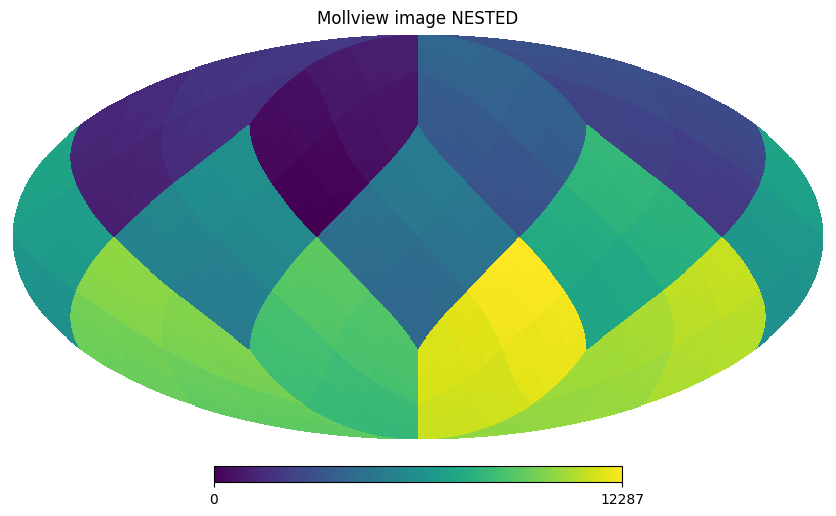

In [12]:
m = np.arange(NPIX)
hp.mollview(m, nest=True, title="Mollview image NESTED")

In [13]:
!wget -c http://lambda.gsfc.nasa.gov/data/map/dr4/skymaps/7yr/raw/wmap_band_iqumap_r9_7yr_W_v4.fits;wget -c http://lambda.gsfc.nasa.gov/data/map/dr4/ancillary/masks/wmap_temperature_analysis_mask_r9_7yr_v4.fits

URL transformed to HTTPS due to an HSTS policy
--2023-10-29 11:56:10--  https://lambda.gsfc.nasa.gov/data/map/dr4/skymaps/7yr/raw/wmap_band_iqumap_r9_7yr_W_v4.fits
Resolving lambda.gsfc.nasa.gov (lambda.gsfc.nasa.gov)... 129.164.179.68
Connecting to lambda.gsfc.nasa.gov (lambda.gsfc.nasa.gov)|129.164.179.68|:443... connected.
HTTP request sent, awaiting response... 416 Requested Range Not Satisfiable

    The file is already fully retrieved; nothing to do.

URL transformed to HTTPS due to an HSTS policy
--2023-10-29 11:56:10--  https://lambda.gsfc.nasa.gov/data/map/dr4/ancillary/masks/wmap_temperature_analysis_mask_r9_7yr_v4.fits
Resolving lambda.gsfc.nasa.gov (lambda.gsfc.nasa.gov)... 129.164.179.68
Connecting to lambda.gsfc.nasa.gov (lambda.gsfc.nasa.gov)|129.164.179.68|:443... connected.
HTTP request sent, awaiting response... 416 Requested Range Not Satisfiable

    The file is already fully retrieved; nothing to do.



In [14]:
wmap_map_I = hp.read_map("wmap_band_iqumap_r9_7yr_W_v4.fits")

In [15]:
hp.write_map("my_map.fits", wmap_map_I, overwrite=True)

setting the output map dtype to [dtype('>f4')]


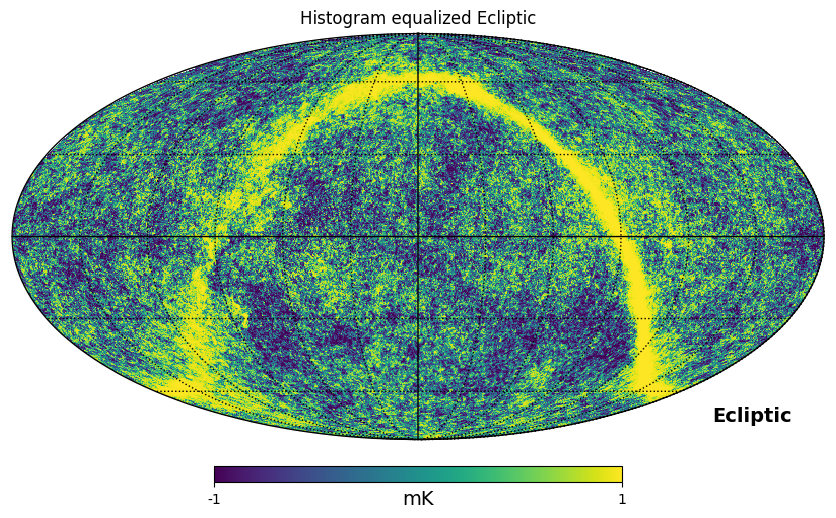

In [16]:
hp.mollview(
    wmap_map_I,
    coord=["G", "E"],
    title="Histogram equalized Ecliptic",
    unit="mK",
    norm="hist",
    min=-1,
    max=1,
)
hp.graticule()

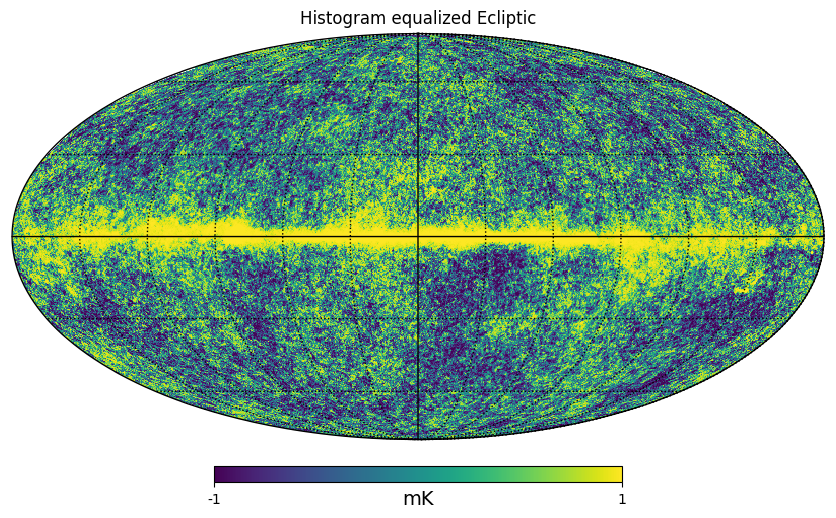

In [17]:
hp.mollview(
    wmap_map_I,
    title="Histogram equalized Ecliptic",
    unit="mK",
    norm="hist",
    min=-1,
    max=1,
)
hp.graticule()

In [18]:
constellation_line_path = "/Users/nobody/Projects/Astro/Workflow2/catalogs/sfa_constellation_lines.csv"
import csv
with open(constellation_line_path) as csvfile:
    reader = csv.reader(csvfile, delimiter=',')
    num_rows = 0
    for row in reader:
        assert len(row) == 14
        if num_rows < 30:
          print(f"{len(row)}:  {' '.join(row)}")
        num_rows += 1

14:               
14:  Constellation Lines             
14:  Blank rows mean that you should "pick up your pen" when drawing the constellations.             
14:  Dan Bruton, SFA Observatory, astro@sfasu.edu, http://observe.phy.sfasu.edu/             
14:  Epoch 2000 - Tab Delimited             
14:               
14:  CON NAME RA DEC MAG  RA(North) DEC(North)  RA(South) DEC(South)  SYMBOL 
14:               
14:  ORI pi^2 4.843611 8.9000 4.30  77.4118 24.1790  -94.4023 -29.4859  π2 
14:  ORI pi^3 4.830833 6.9500 3.10  79.1898 25.0255  -92.4438 -29.2139  π3 
14:  ORI pi^4 4.853611 5.6000 3.60  80.6273 24.9519  -91.3267 -28.2630  π4 
14:  ORI pi^5 4.904167 2.4500 3.70  83.9717 24.7740  -88.6715 -26.1605  π5 
14:  ORI pi^6 4.975833 1.7167 4.40  85.1289 23.3885  -88.4395 -24.2980  π6 
14:  ORI gamma 5.418889 6.3500 1.60  82.6838 12.6770  -95.2371 -14.6017  γ 
14:  ORI delta 5.533611 -0.3000 2.20  89.3300 10.9617  -89.3300 -10.9617  δ 
14:  ORI eta 5.408056 -2.3833 3.30  91.2762 14.2595  

In [19]:
ra_list, dec_list = np.linspace(0, 24, 100), np.linspace(10, 10, 100)
ra_list

array([ 0.        ,  0.24242424,  0.48484848,  0.72727273,  0.96969697,
        1.21212121,  1.45454545,  1.6969697 ,  1.93939394,  2.18181818,
        2.42424242,  2.66666667,  2.90909091,  3.15151515,  3.39393939,
        3.63636364,  3.87878788,  4.12121212,  4.36363636,  4.60606061,
        4.84848485,  5.09090909,  5.33333333,  5.57575758,  5.81818182,
        6.06060606,  6.3030303 ,  6.54545455,  6.78787879,  7.03030303,
        7.27272727,  7.51515152,  7.75757576,  8.        ,  8.24242424,
        8.48484848,  8.72727273,  8.96969697,  9.21212121,  9.45454545,
        9.6969697 ,  9.93939394, 10.18181818, 10.42424242, 10.66666667,
       10.90909091, 11.15151515, 11.39393939, 11.63636364, 11.87878788,
       12.12121212, 12.36363636, 12.60606061, 12.84848485, 13.09090909,
       13.33333333, 13.57575758, 13.81818182, 14.06060606, 14.3030303 ,
       14.54545455, 14.78787879, 15.03030303, 15.27272727, 15.51515152,
       15.75757576, 16.        , 16.24242424, 16.48484848, 16.72

In [20]:
phis = [np.deg2rad(ra) for ra in ra_list]
thetas = [np.pi / 2 - np.deg2rad(dec) for dec in dec_list]

In [21]:
print('phis', phis)
print('thetas', thetas)

phis [0.0, 0.004231101216955951, 0.008462202433911901, 0.012693303650867852, 0.016924404867823803, 0.021155506084779754, 0.025386607301735704, 0.029617708518691655, 0.033848809735647606, 0.03807991095260355, 0.04231101216955951, 0.04654211338651546, 0.05077321460347141, 0.055004315820427356, 0.05923541703738331, 0.06346651825433926, 0.06769761947129521, 0.07192872068825115, 0.0761598219052071, 0.08039092312216306, 0.08462202433911901, 0.08885312555607495, 0.09308422677303092, 0.09731532798998686, 0.10154642920694282, 0.10577753042389876, 0.11000863164085471, 0.11423973285781067, 0.11847083407476662, 0.12270193529172256, 0.12693303650867852, 0.13116413772563448, 0.13539523894259042, 0.13962634015954636, 0.1438574413765023, 0.14808854259345824, 0.1523196438104142, 0.15655074502737018, 0.16078184624432612, 0.16501294746128206, 0.16924404867823803, 0.17347514989519397, 0.1777062511121499, 0.18193735232910585, 0.18616845354606185, 0.1903995547630178, 0.19463065597997373, 0.19886175719692967

In [22]:
pixel_indices = hp.ang2pix(NSIDE, thetas, phis)
pixel_indices

array([4928, 4928, 5056, 5056, 5056, 5056, 5056, 5056, 5056, 5056, 4929,
       4929, 4929, 4929, 5057, 5057, 5057, 5057, 5057, 5057, 5057, 5057,
       4930, 4930, 4930, 4930, 5058, 5058, 5058, 5058, 5058, 5058, 5058,
       4931, 4931, 4931, 4931, 5059, 5059, 5059, 5059, 5059, 5059, 5059,
       5059, 4932, 4932, 4932, 4932, 5060, 5060, 5060, 5060, 5060, 5060,
       5060, 5060, 4933, 4933, 4933, 5061, 5061, 5061, 5061, 5061, 5061,
       5061, 5061, 4934, 4934, 4934, 4934, 5062, 5062, 5062, 5062, 5062,
       5062, 5062, 5062, 4935, 4935, 4935, 4935, 5063, 5063, 5063, 5063,
       5063, 5063, 5063, 4936, 4936, 4936, 4936, 5064, 5064, 5064, 5064,
       5064])

In [23]:
np.min(wmap_map_I), np.max(wmap_map_I)

(-0.5256452, 60.36048)

In [24]:
# import copy
# wmap_copy = copy.copy(wmap_map_I)
wmap_copy = np.zeros_like(wmap_map_I)
wmap_copy[pixel_indices] = 1

In [25]:
np.min(wmap_copy), np.max(wmap_copy)

(0.0, 1.0)

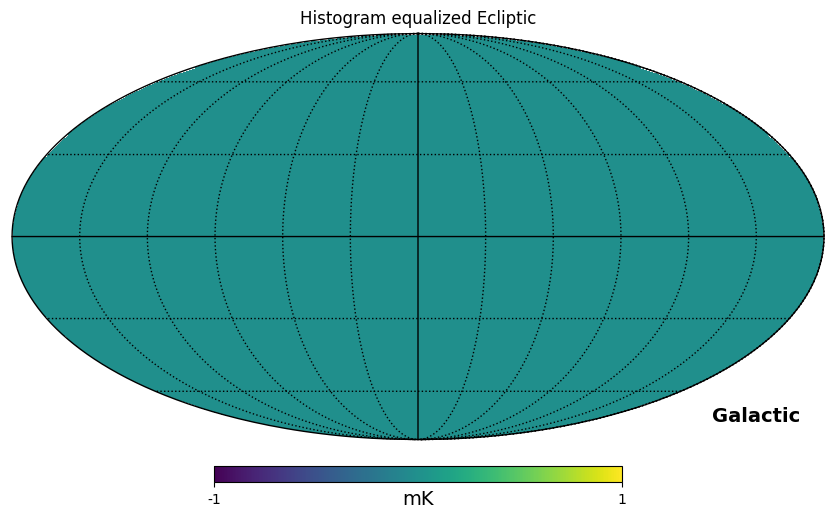

In [26]:
hp.mollview(
    wmap_copy,
    coord=['C', 'G'],
    title="Histogram equalized Ecliptic",
    unit="mK",
    norm="hist",
    min=-1,
    max=1,
)
hp.graticule()

In [16]:
import healpy
import numpy as np

rotator = healpy.rotator.Rotator(coord=['C', 'C'], deg=True)
theta, phi = rotator(7.400, 15 * 5.919444)
print('theta', theta, 'phi', phi)

theta 1.116814692820414 phi 0.8270656994857967


In [17]:
np.rad2deg(theta), np.rad2deg(phi)

(63.9887683968092, 47.38737396057141)

In [43]:
import healpy as hp
import numpy as np
r = hp.Rotator(coord = ['G', 'C'])
ri = hp.Rotator(coord = ['C', 'G'])
gz, ga = np.pi/2, 0.         # position of GC
gz_e, ga_e = r(gz, ga)

print("Galactic center in Celestial Coordinates")
print(gz_e, ga_e)
zg, ag = ri(gz_e, ga_e)
print("Back to galactic coordinates")
print(zg, ag)

Galactic center in Celestial Coordinates
2.075827808158804 -1.633540979132799
Back to galactic coordinates
1.5707963267948966 -2.8002698479364083e-16


In [93]:
ri = hp.Rotator(coord = ['C', 'G'])

dec, ra = np.radians(-7.400 + 90), np.radians(360 - (15 * 5.919444))
print('dec', dec, 'ra', ra)

lat, lon = ri(dec, ra)
print('In Galactic coordinates')
print('rad', lat, lon)
print('deg', np.degrees(lat), np.degrees(lon))

print('deg', -np.degrees(lat - (np.pi/2)), np.degrees((2*np.pi) - lon))

dec 1.4416419621473162 ra 4.733478491868238
In Galactic coordinates
rad 1.3315538321272586 0.5987625907476817
deg 76.29241477536324 34.306569380161115
deg 13.707585224636755 325.69343061983886


In [285]:
def _solve_theta(phi):
  theta = 0
  for i in range(10):
    theta = theta - (2 * theta + np.sin(2 * theta) -
                    np.pi * np.sin(phi)) / (4 * np.cos(theta)**2.0)

  return theta


def _project_Mollweide(lon, lat, R=45*np.sqrt(2)):
  lon_0 = 0
  theta = _solve_theta(lat)
  x = R * (2 * np.sqrt(2) / np.pi) * (lon - lon_0) * np.cos(theta)
  y = R * np.sqrt(2) * np.sin(theta)

  return (x, y)

In [286]:
from astropy.coordinates import SkyCoord

# Galactic center
lon = 15 * (17 + (45/60) + (40.04/3600))
lat = -29 + (0/60) + (28.1/3600)
eq = SkyCoord(lon, lat, unit='deg')
l, b = eq.galactic.l.value, eq.galactic.b.value
print('l', l, 'b', b)

l 359.95758537707997 b -0.038029867922062525


In [287]:
# Betelgeuse
lon = 15 * (5 + (55/60) + (10.30536/3600))
lat = 7 + (24/60) + (25.4304/3600)
eq = SkyCoord(lon, lat, unit='deg')
l, b = eq.galactic.l.value, eq.galactic.b.value
print('l', l, 'b', b)

l 199.78723618669392 b -8.958603275676376


In [288]:
# gamma Sag
ra_string = "18.096667"
dec_string = "-30.4333"

eq = SkyCoord(15 * float(ra_string), float(dec_string), unit='deg')
theta = np.radians(eq.galactic.l.value)
phi = np.radians(eq.galactic.b.value)
print('theta', theta, 'phi', phi)

x, y = _project_Mollweide(theta, phi)
print('x', x, 'y', y)

theta 0.01587647794917053 phi -0.07925500146946314
x 0.9078925858009269 y -5.599958386284496


In [289]:
_project_Mollweide(np.radians(0), np.radians(0))

(0.0, 0.0)

In [290]:
_project_Mollweide(np.radians(10), np.radians(0))

(10.000000000000002, 0.0)

In [291]:
_project_Mollweide(np.radians(50), np.radians(0))

(50.00000000000001, 0.0)

In [292]:
_project_Mollweide(np.radians(179), np.radians(0))

(179.00000000000003, 0.0)

In [298]:
_project_Mollweide(np.radians(359), np.radians(0))

(359.00000000000006, 0.0)

In [293]:
_project_Mollweide(np.radians(-179), np.radians(0))

(-179.00000000000003, 0.0)

In [294]:
_project_Mollweide(np.radians(0), np.radians(10))

(0.0, 12.312985798231074)

In [295]:
_project_Mollweide(np.radians(0), np.radians(45))

(0.0, 53.283757484903425)

In [296]:
_project_Mollweide(np.radians(0), np.radians(89))

(0.0, 89.77269681915435)

In [297]:
_project_Mollweide(np.radians(179), np.radians(89))

(12.713793254595258, 89.77269681915435)